In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [2]:
PROCESSED_DIR = Path("../data/processed")
PM25_PATH = PROCESSED_DIR / "pm25_selected_station_days.parquet"
PM10_PATH = PROCESSED_DIR / "pm10_selected_station_days.parquet"
TARGETS = ["pm25", "pm10"]

In [3]:
sns.set_theme(style="whitegrid", context="notebook")

In [4]:
pm25_df = pd.read_parquet(PM25_PATH)
pm10_df = pd.read_parquet(PM10_PATH)
df = pd.concat([pm25_df, pm10_df], ignore_index=True).drop_duplicates(subset=["station_id", "date"])
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year

print(f"Shape: {df.shape}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Stations: {df['station_id'].nunique()}")
display(df.head(30))


Shape: (9441, 78)
Date range: 2016-12-11 to 2025-12-31
Stations: 6


,station_id,station_name,date,co,no,no2,o3,pm10,pm25,so2,...,soil_moisture_100_to_255cm_mean,month,day_of_week,is_weekend,season,rain_indicator,wind_category,pm_violation_diff,large_pm10_lt_pm25_flag,year
0,2919,Gazi Baba,2023-06-27,233.250000,62.066667,1.083458,83.816667,18.000000,9.475000,0.002017,...,0.192750,6,1,0,summer,1,weak,-8.525000,False,2023
1,2919,Gazi Baba,2023-06-28,206.083333,61.545833,1.115375,69.883333,22.347083,11.458333,0.001937,...,0.180000,6,2,0,summer,0,weak,-10.888750,False,2023
2,2919,Gazi Baba,2023-06-29,232.375000,53.700000,0.939250,71.633333,9.240417,6.600000,0.001775,...,0.180000,6,3,0,summer,1,weak,-2.640417,False,2023
3,2919,Gazi Baba,2023-06-30,265.750000,59.779167,1.210292,65.808333,17.250000,10.837500,0.001862,...,0.180000,6,4,0,summer,0,weak,-6.412500,False,2023
4,2919,Gazi Baba,2023-07-01,306.208333,62.562500,1.179583,59.150000,18.296667,10.291667,0.001975,...,0.180000,7,5,1,summer,0,weak,-8.005000,False,2023
5,2919,Gazi Baba,2023-07-02,193.358333,66.462500,0.924333,60.816667,12.014167,7.208333,0.001958,...,0.180000,7,6,1,summer,1,weak,-4.805833,False,2023
6,2919,Gazi Baba,2023-07-03,145.566667,62.800000,1.059000,64.758333,16.248333,9.783333,0.002087,...,0.180000,7,0,0,summer,0,weak,-6.465000,False,2023
7,2919,Gazi Baba,2023-07-04,158.125000,63.133333,1.171000,63.141667,15.082917,7.033333,0.002471,...,0.180000,7,1,0,summer,0,weak,-8.049583,False,2023
8,2919,Gazi Baba,2023-07-05,142.433333,75.525000,1.019792,67.733333,14.270833,7.812500,0.001904,...,0.180000,7,2,0,summer,1,weak,-6.458333,False,2023
9,2919,Gazi Baba,2023-07-06,112.820833,60.525000,1.055217,85.241667,12.232500,5.562500,0.001233,...,0.180000,7,3,0,summer,0,weak,-6.670000,False,2023


In [5]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
}).sort_values(["missing_pct", "missing"], ascending=False)

display(overview)

availability = pd.DataFrame({
    "valid_days": [df[target].notna().sum() for target in TARGETS],
    "missing_days": [df[target].isna().sum() for target in TARGETS],
    "coverage_pct": [(df[target].notna().mean() * 100).round(2) for target in TARGETS],
}, index=[target.upper() for target in TARGETS])
display(availability)

if "large_pm10_lt_pm25_flag" in df.columns:
    print(f"Large PM2.5 > PM10 flags: {df['large_pm10_lt_pm25_flag'].sum():,} / {len(df):,}")


,dtype,missing,missing_pct,unique
no,float64,8575,90.83,841
no_observed_hours,float64,8552,90.58,20
no_valid_day,object,8552,90.58,2
pm_violation_diff,float64,5996,63.51,3417
pm25,float64,5446,57.68,3804
...,...,...,...,...
season,str,0,0.00,4
rain_indicator,int64,0,0.00,2
wind_category,category,0,0.00,2
large_pm10_lt_pm25_flag,bool,0,0.00,2


,valid_days,missing_days,coverage_pct
PM25,3995,5446,42.32
PM10,8891,550,94.17


Large PM2.5 > PM10 flags: 34 / 9,441


In [6]:
summary = df.groupby(["station_id", "station_name"], dropna=False).agg(
    first_date=("date", "min"),
    last_date=("date", "max"),
    total_days=("date", "size"),
    pm25_valid_days=("pm25", "count"),
    pm25_mean=("pm25", "mean"),
    pm25_median=("pm25", "median"),
    pm10_valid_days=("pm10", "count"),
    pm10_mean=("pm10", "mean"),
    pm10_median=("pm10", "median"),
).reset_index()

display(summary.sort_values("pm25_valid_days", ascending=False))


,station_id,station_name,first_date,last_date,total_days,pm25_valid_days,pm25_mean,pm25_median,pm10_valid_days,pm10_mean,pm10_median
2,2977,Karpos,2016-12-11,2025-12-31,1963,1334,25.979264,19.296785,1811,46.050690,35.141667
5,2996,Centar,2016-12-11,2025-12-31,1958,1284,25.730671,21.186364,1928,47.292826,38.187311
0,2919,Gazi Baba,2016-12-11,2025-12-31,1733,463,20.459134,12.816667,1733,41.179405,29.970000
3,2978,Miladinovci,2023-06-27,2025-12-31,459,459,19.805285,12.172727,93,32.678909,26.028571
1,2976,Lisice,2016-12-11,2025-12-31,1674,455,24.038734,15.747368,1672,55.951895,37.433333
4,2979,Rektorat,2016-12-11,2024-08-25,1654,0,NaN,NaN,1654,54.563450,41.566268


In [7]:
display(df[TARGETS].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
pm25,3995.0,24.329249,21.195360,0.0,2.726611,5.417174,10.681469,17.933333,29.643750,68.047500,106.650906,253.738889
pm10,8891.0,48.676294,39.437639,0.0,9.708754,14.983125,25.533333,36.691304,56.435088,128.036111,208.137826,435.681818


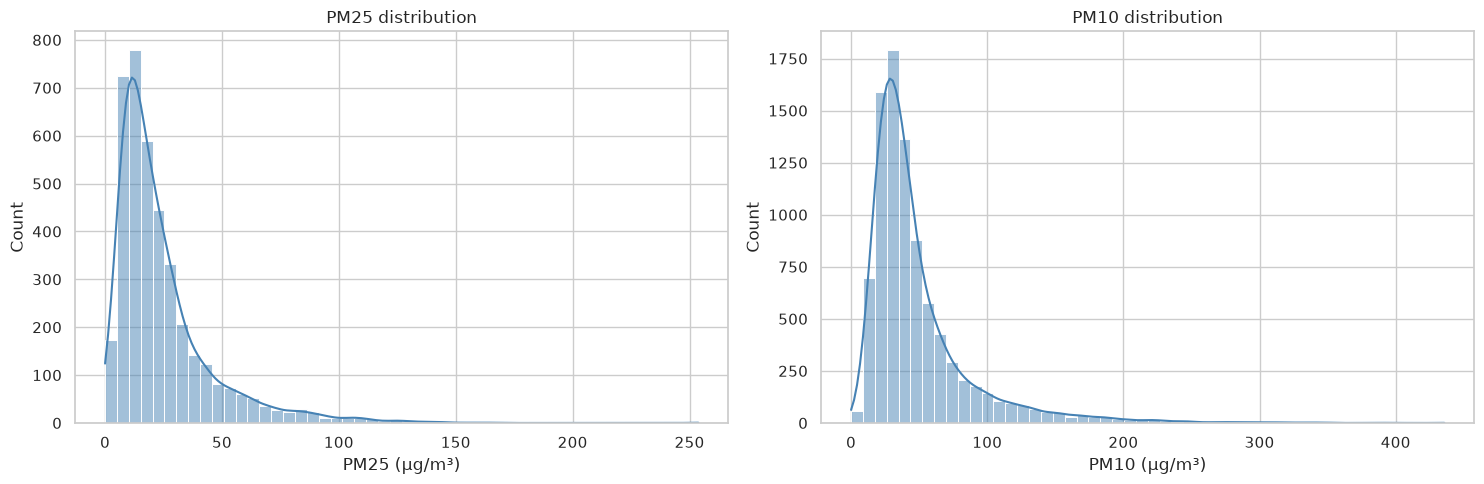

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, target in zip(axes, TARGETS):
    sns.histplot(data=df, x=target, bins=50, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{target.upper()} distribution")
    ax.set_xlabel(f"{target.upper()} (µg/m³)")

plt.tight_layout()
plt.show()


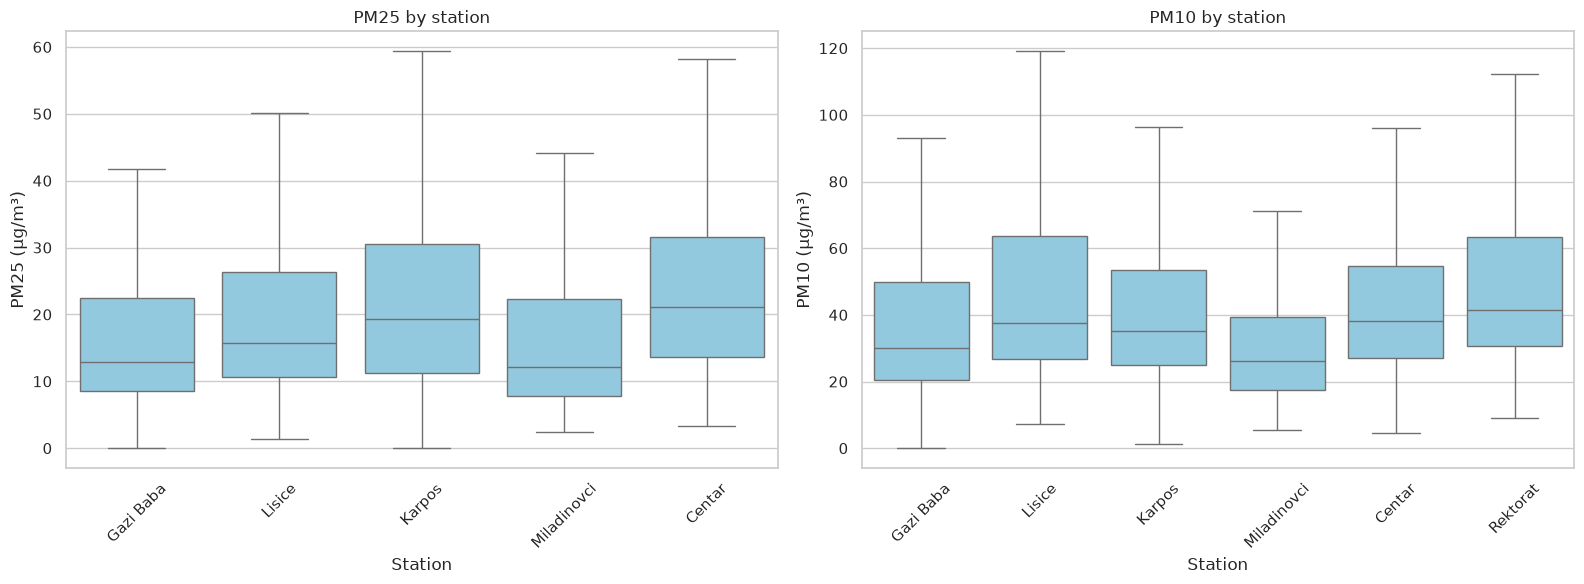

In [9]:
long_df = df.melt(
    id_vars=["station_name"],
    value_vars=TARGETS,
    var_name="pollutant",
    value_name="concentration",
).dropna(subset=["concentration"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False)

for ax, target in zip(axes, TARGETS):
    plot_df = long_df[long_df["pollutant"] == target]
    sns.boxplot(data=plot_df, x="station_name", y="concentration", ax=ax, color="skyblue", showfliers=False)
    ax.set_title(f"{target.upper()} by station")
    ax.set_xlabel("Station")
    ax.set_ylabel(f"{target.upper()} (µg/m³)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


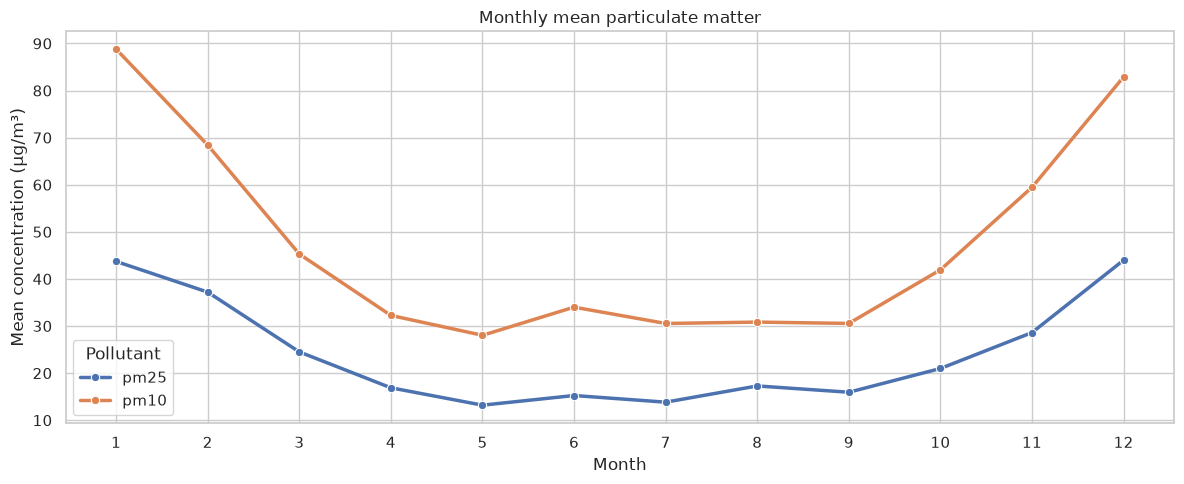

,month,pm25,pm10
0,1,43.71,88.79
1,2,37.20,68.42
2,3,24.51,45.29
3,4,16.88,32.25
4,5,13.20,28.03
5,6,15.25,34.01
6,7,13.83,30.54
7,8,17.28,30.83
8,9,15.94,30.56
9,10,20.98,41.94


In [10]:
monthly = df.groupby("month")[TARGETS].mean().reset_index()
monthly_long = monthly.melt(id_vars="month", var_name="pollutant", value_name="mean_concentration")

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_long, x="month", y="mean_concentration", hue="pollutant", marker="o", linewidth=2.5)
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Mean concentration (µg/m³)")
plt.title("Monthly mean particulate matter")
plt.legend(title="Pollutant")
plt.tight_layout()
plt.show()

display(monthly.round(2))


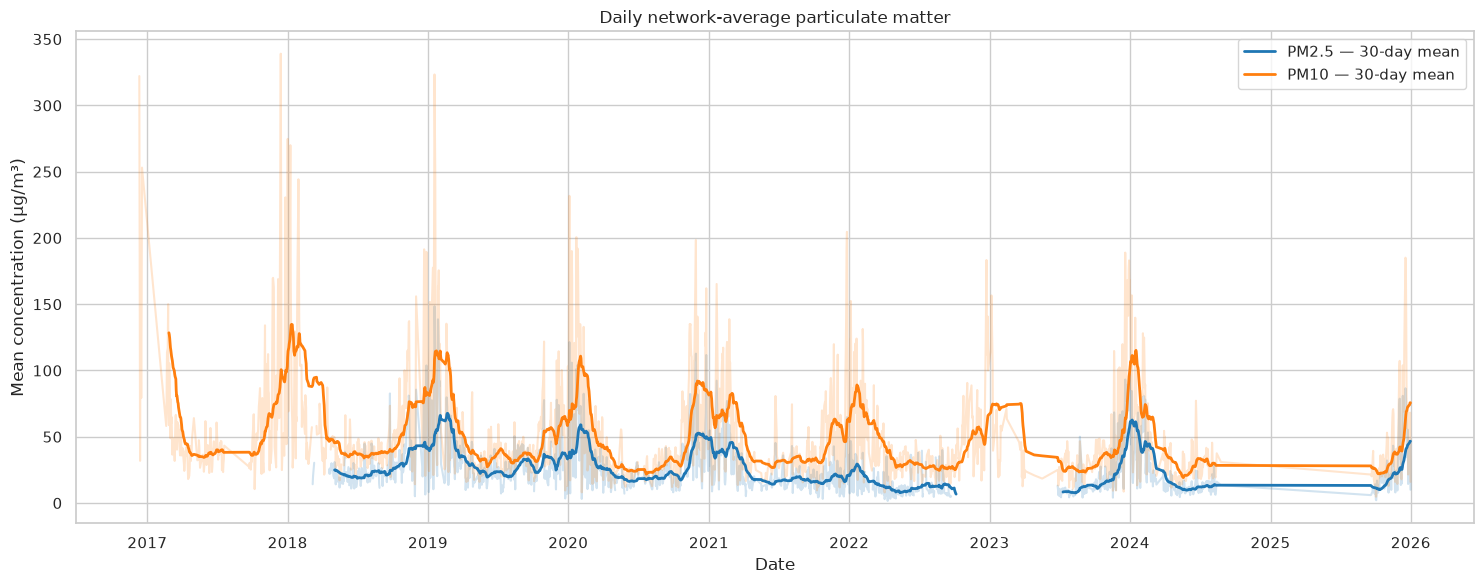

In [11]:
daily = df.groupby("date")[TARGETS].mean().sort_index()
rolling = daily.rolling(30, min_periods=15).mean()

plt.figure(figsize=(15, 6))
plt.plot(daily.index, daily["pm25"], alpha=0.20, color="tab:blue")
plt.plot(daily.index, daily["pm10"], alpha=0.20, color="tab:orange")
plt.plot(rolling.index, rolling["pm25"], label="PM2.5 — 30-day mean", color="tab:blue", linewidth=2)
plt.plot(rolling.index, rolling["pm10"], label="PM10 — 30-day mean", color="tab:orange", linewidth=2)
plt.xlabel("Date")
plt.ylabel("Mean concentration (µg/m³)")
plt.title("Daily network-average particulate matter")
plt.legend()
plt.tight_layout()
plt.show()


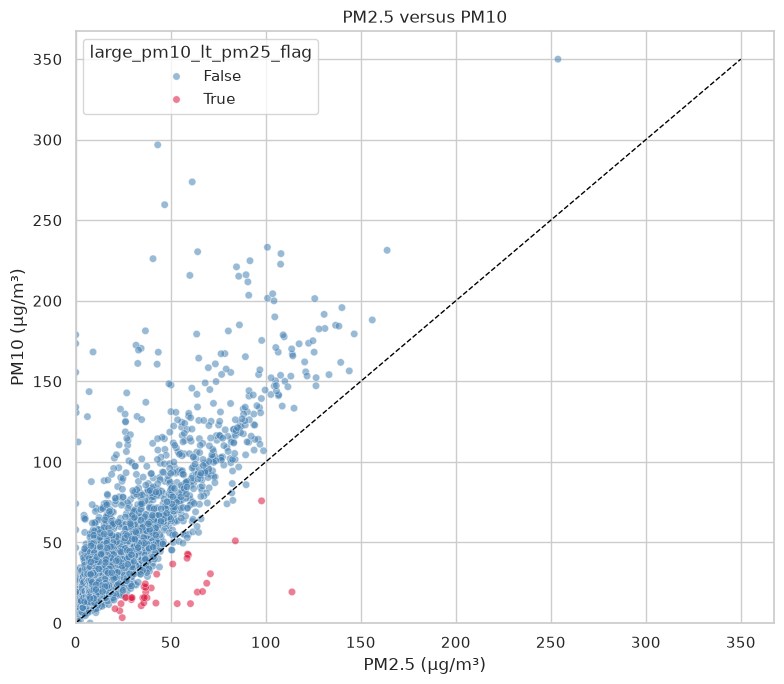

PM2.5–PM10 correlation: 0.815


In [12]:
scatter_cols = ["pm25", "pm10"]
if "large_pm10_lt_pm25_flag" in df.columns:
    scatter_cols.append("large_pm10_lt_pm25_flag")

scatter_df = df[scatter_cols].dropna(subset=["pm25", "pm10"]).copy()

plt.figure(figsize=(8, 7))
if "large_pm10_lt_pm25_flag" in scatter_df.columns:
    sns.scatterplot(
        data=scatter_df,
        x="pm25",
        y="pm10",
        hue="large_pm10_lt_pm25_flag",
        palette={False: "steelblue", True: "crimson"},
        alpha=0.55,
        s=28,
    )
else:
    sns.scatterplot(data=scatter_df, x="pm25", y="pm10", alpha=0.55, s=28, color="steelblue")

limit = max(scatter_df["pm25"].max(), scatter_df["pm10"].max())
plt.plot([0, limit], [0, limit], linestyle="--", color="black", linewidth=1)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("PM10 (µg/m³)")
plt.title("PM2.5 versus PM10")
plt.tight_layout()
plt.show()

print(f"PM2.5–PM10 correlation: {scatter_df['pm25'].corr(scatter_df['pm10']):.3f}")


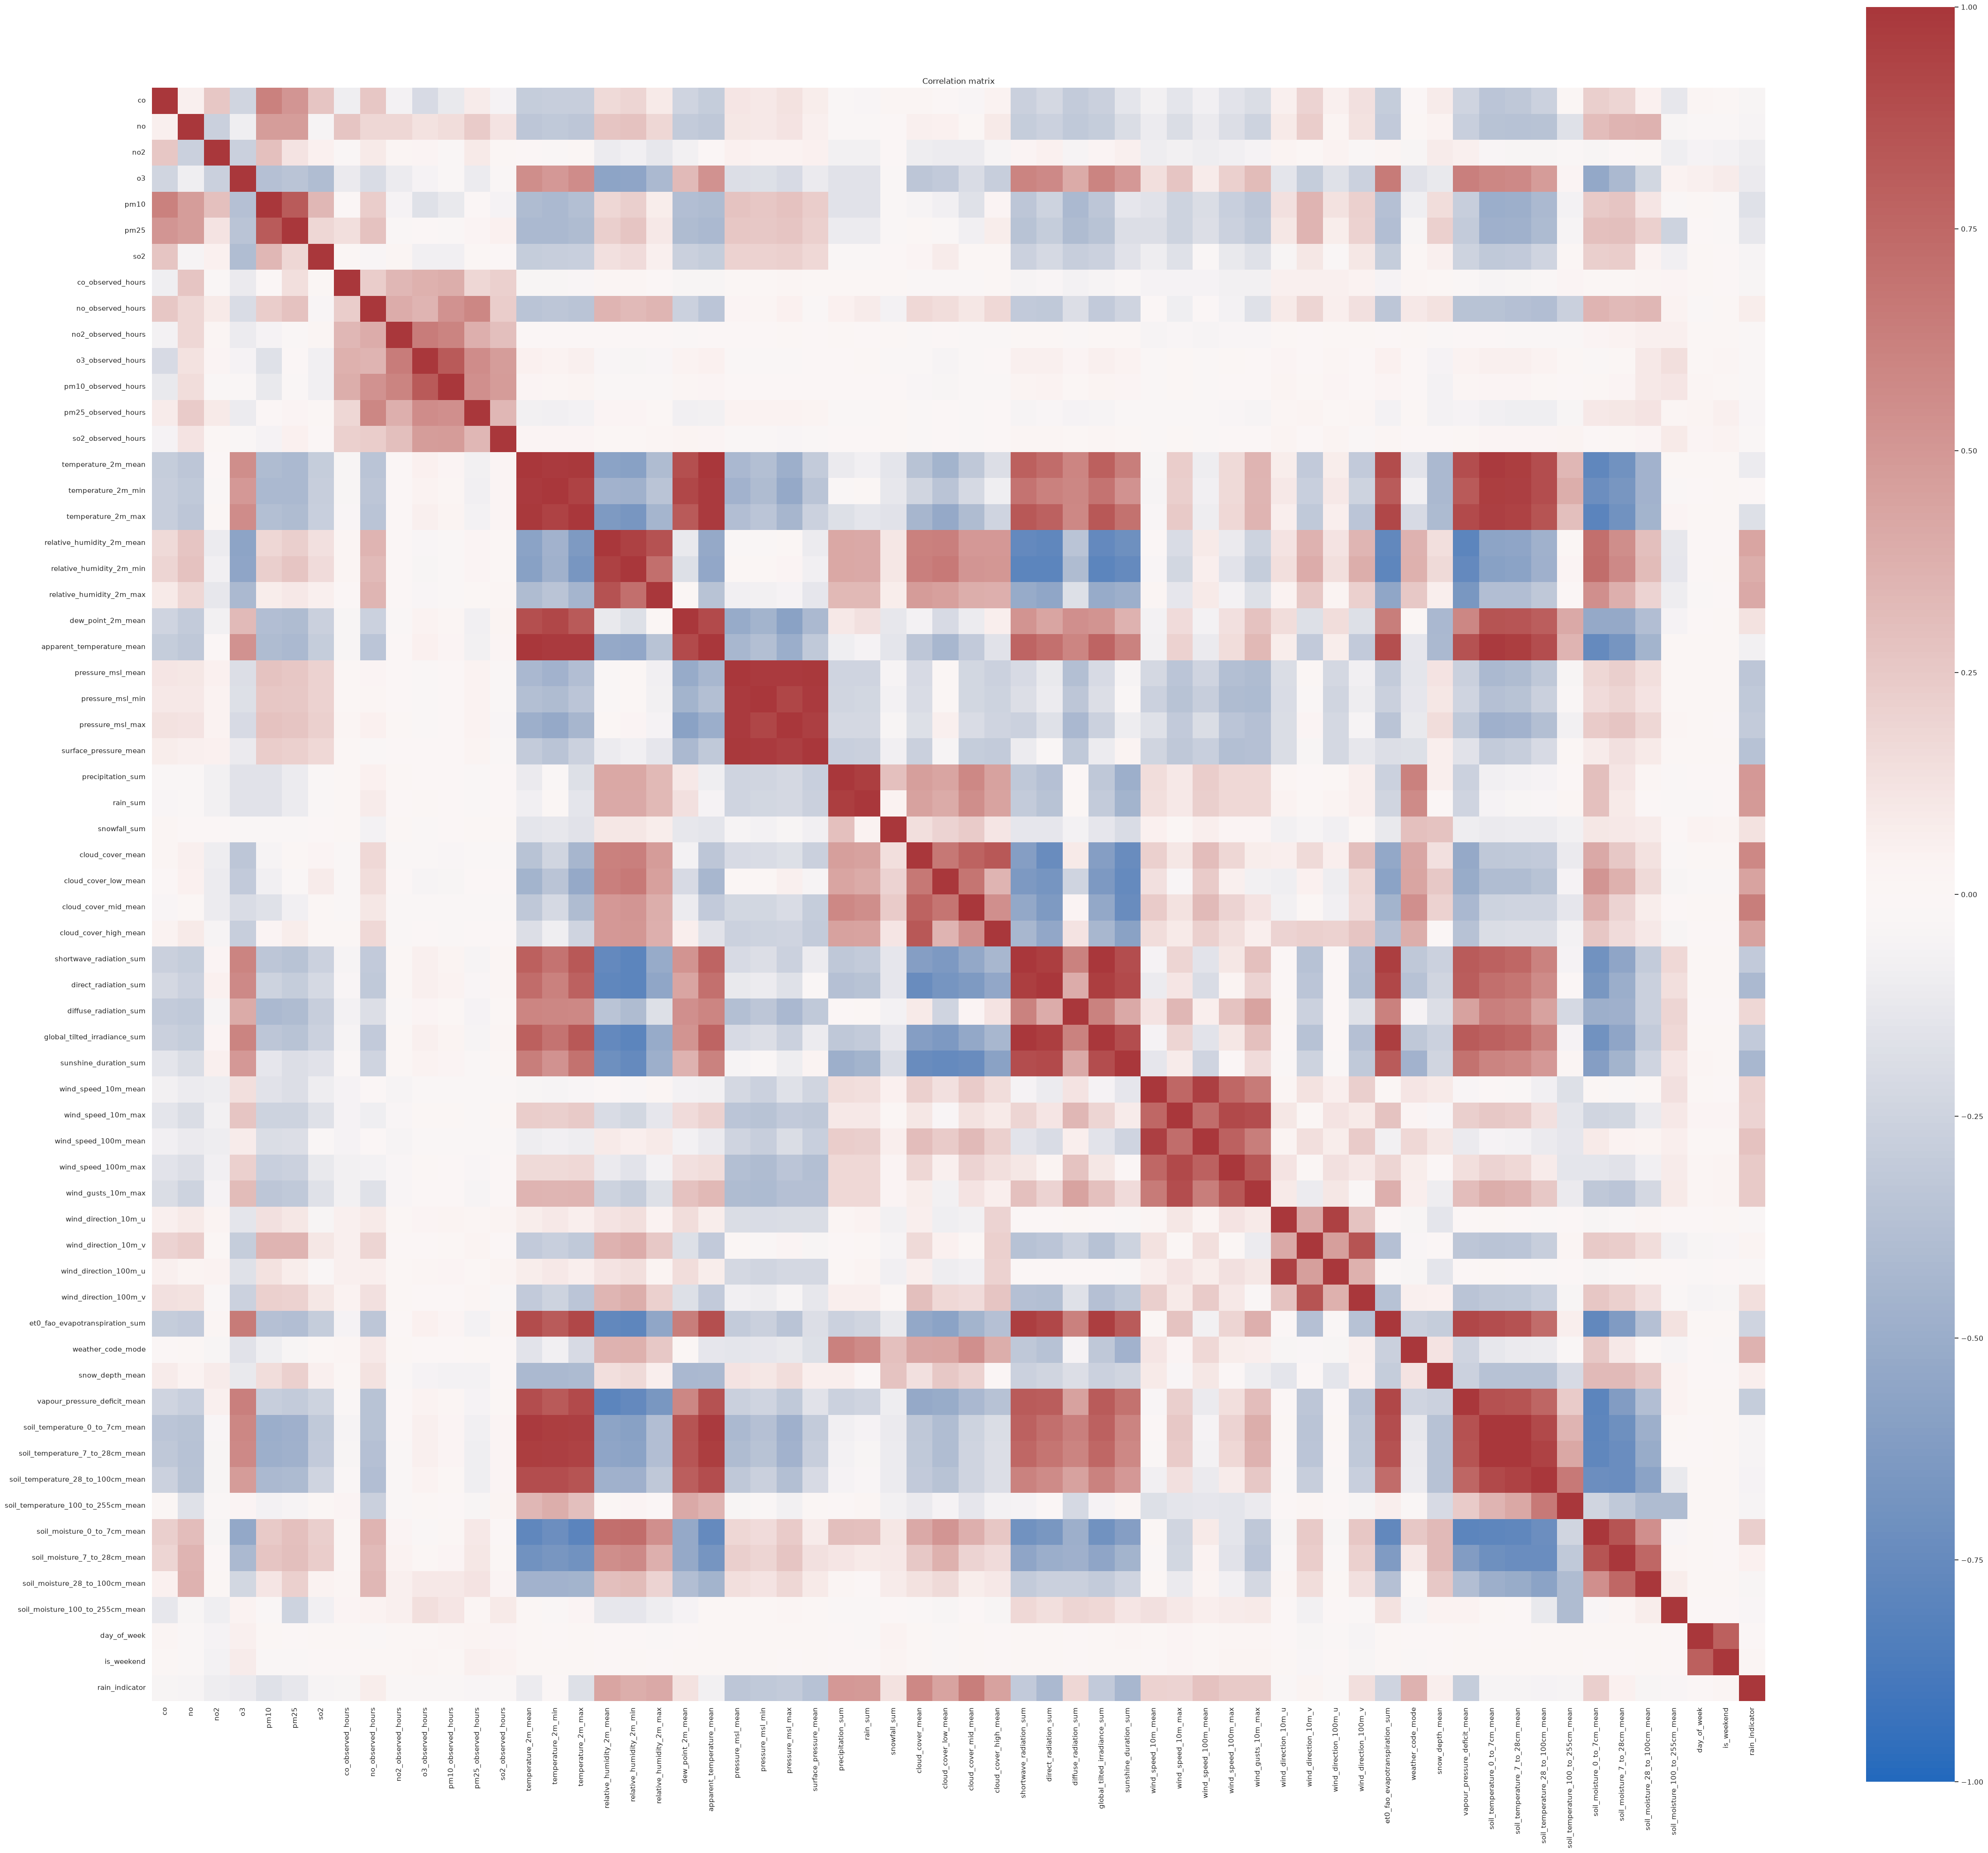

,pm25,pm10
pm25,1.000000,0.814722
pm10,0.814722,1.000000
co,0.512349,0.624645
no,0.471395,0.470503
wind_direction_10m_v,0.354302,0.355059
...,...,...
apparent_temperature_mean,-0.417997,-0.403679
temperature_2m_mean,-0.419484,-0.405992
temperature_2m_min,-0.421779,-0.414764
soil_temperature_7_to_28cm_mean,-0.476351,-0.485698


In [13]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
excluded = {"station_id", "month", "year", "pm_violation_diff"}
corr_cols = [col for col in numeric_cols if col not in excluded]

corr = df[corr_cols].corr()

plt.figure(figsize=(max(10, len(corr_cols) * 0.75), max(8, len(corr_cols) * 0.65)))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

display(corr.loc[TARGETS].T.sort_values("pm25", ascending=False))


In [14]:
exclude_cols = {
    "station_id",
    "month",
    "year",
    "pm25",
    "pm10",
    "large_pm10_lt_pm25_flag",
    "pm_violation_diff",
}

same_day_pollutant_cols = [col for col in ["co", "no", "no2", "o3", "so2"] if col in df.columns]

numeric_candidate_cols = [
    col for col in df.select_dtypes(include="number").columns
    if col not in exclude_cols and not col.endswith("_observed_hours")
]

feature_cols = [col for col in numeric_candidate_cols if col not in same_day_pollutant_cols]

print("pm_violation_diff excluded: it is built from pm25/pm10 themselves (circular).")
print(f"{len(numeric_candidate_cols)} numeric candidates "
      f"({len(feature_cols)} model-usable + {len(same_day_pollutant_cols)} same-day co-pollutants)")
display(feature_cols)
display(same_day_pollutant_cols)


pm_violation_diff excluded: it is built from pm25/pm10 themselves (circular).
53 numeric candidates (48 model-usable + 5 same-day co-pollutants)


['temperature_2m_mean',
 'temperature_2m_min',
 'temperature_2m_max',
 'relative_humidity_2m_mean',
 'relative_humidity_2m_min',
 'relative_humidity_2m_max',
 'dew_point_2m_mean',
 'apparent_temperature_mean',
 'pressure_msl_mean',
 'pressure_msl_min',
 'pressure_msl_max',
 'surface_pressure_mean',
 'precipitation_sum',
 'rain_sum',
 'snowfall_sum',
 'cloud_cover_mean',
 'cloud_cover_low_mean',
 'cloud_cover_mid_mean',
 'cloud_cover_high_mean',
 'shortwave_radiation_sum',
 'direct_radiation_sum',
 'diffuse_radiation_sum',
 'global_tilted_irradiance_sum',
 'sunshine_duration_sum',
 'wind_speed_10m_mean',
 'wind_speed_10m_max',
 'wind_speed_100m_mean',
 'wind_speed_100m_max',
 'wind_gusts_10m_max',
 'wind_direction_10m_u',
 'wind_direction_10m_v',
 'wind_direction_100m_u',
 'wind_direction_100m_v',
 'et0_fao_evapotranspiration_sum',
 'weather_code_mode',
 'snow_depth_mean',
 'vapour_pressure_deficit_mean',
 'soil_temperature_0_to_7cm_mean',
 'soil_temperature_7_to_28cm_mean',
 'soil_temp

['co', 'no', 'no2', 'o3', 'so2']

In [15]:
target_corr = (
    df[feature_cols + TARGETS]
    .corr()
    .loc[feature_cols, TARGETS]
)

target_corr["max_abs_corr"] = target_corr.abs().max(axis=1)

target_corr = target_corr.sort_values("max_abs_corr", ascending=False)

display(target_corr.round(3))


,pm25,pm10,max_abs_corr
soil_temperature_0_to_7cm_mean,-0.483,-0.492,0.492
soil_temperature_7_to_28cm_mean,-0.476,-0.486,0.486
temperature_2m_min,-0.422,-0.415,0.422
diffuse_radiation_sum,-0.405,-0.421,0.421
temperature_2m_mean,-0.419,-0.406,0.419
apparent_temperature_mean,-0.418,-0.404,0.418
soil_temperature_28_to_100cm_mean,-0.412,-0.418,0.418
dew_point_2m_mean,-0.403,-0.389,0.403
temperature_2m_max,-0.401,-0.377,0.401
et0_fao_evapotranspiration_sum,-0.387,-0.370,0.387


In [16]:
co_pollutant_corr = (
    df[same_day_pollutant_cols + TARGETS]
    .corr()
    .loc[same_day_pollutant_cols, TARGETS]
)

co_pollutant_corr["max_abs_corr"] = co_pollutant_corr.abs().max(axis=1)
co_pollutant_corr = co_pollutant_corr.sort_values("max_abs_corr", ascending=False)

display(co_pollutant_corr.round(3))


,pm25,pm10,max_abs_corr
co,0.512,0.625,0.625
no,0.471,0.471,0.471
o3,-0.351,-0.368,0.368
so2,0.181,0.338,0.338
no2,0.122,0.296,0.296


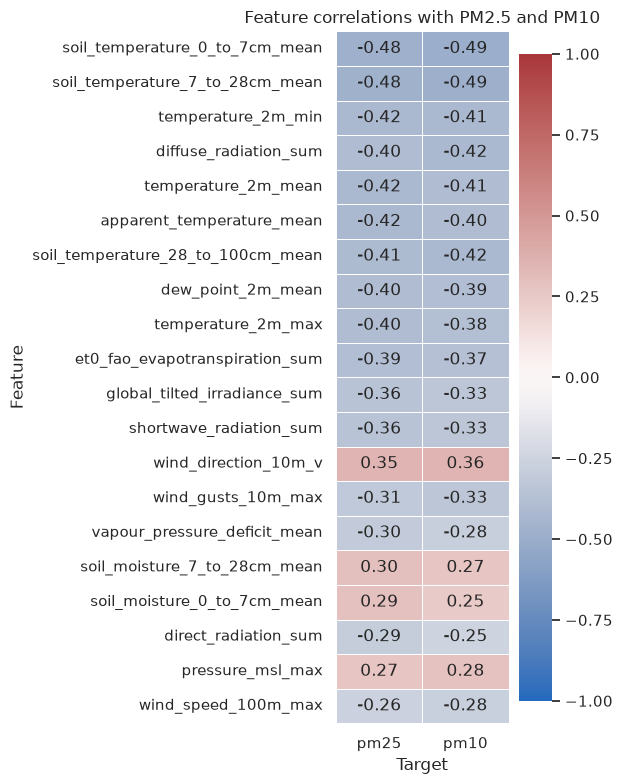

In [17]:
top_features = target_corr.head(20).index.tolist()

plt.figure(figsize=(6, max(6, len(top_features) * 0.4)))

sns.heatmap(
    target_corr.loc[top_features, TARGETS],
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)

plt.title("Feature correlations with PM2.5 and PM10")
plt.xlabel("Target")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


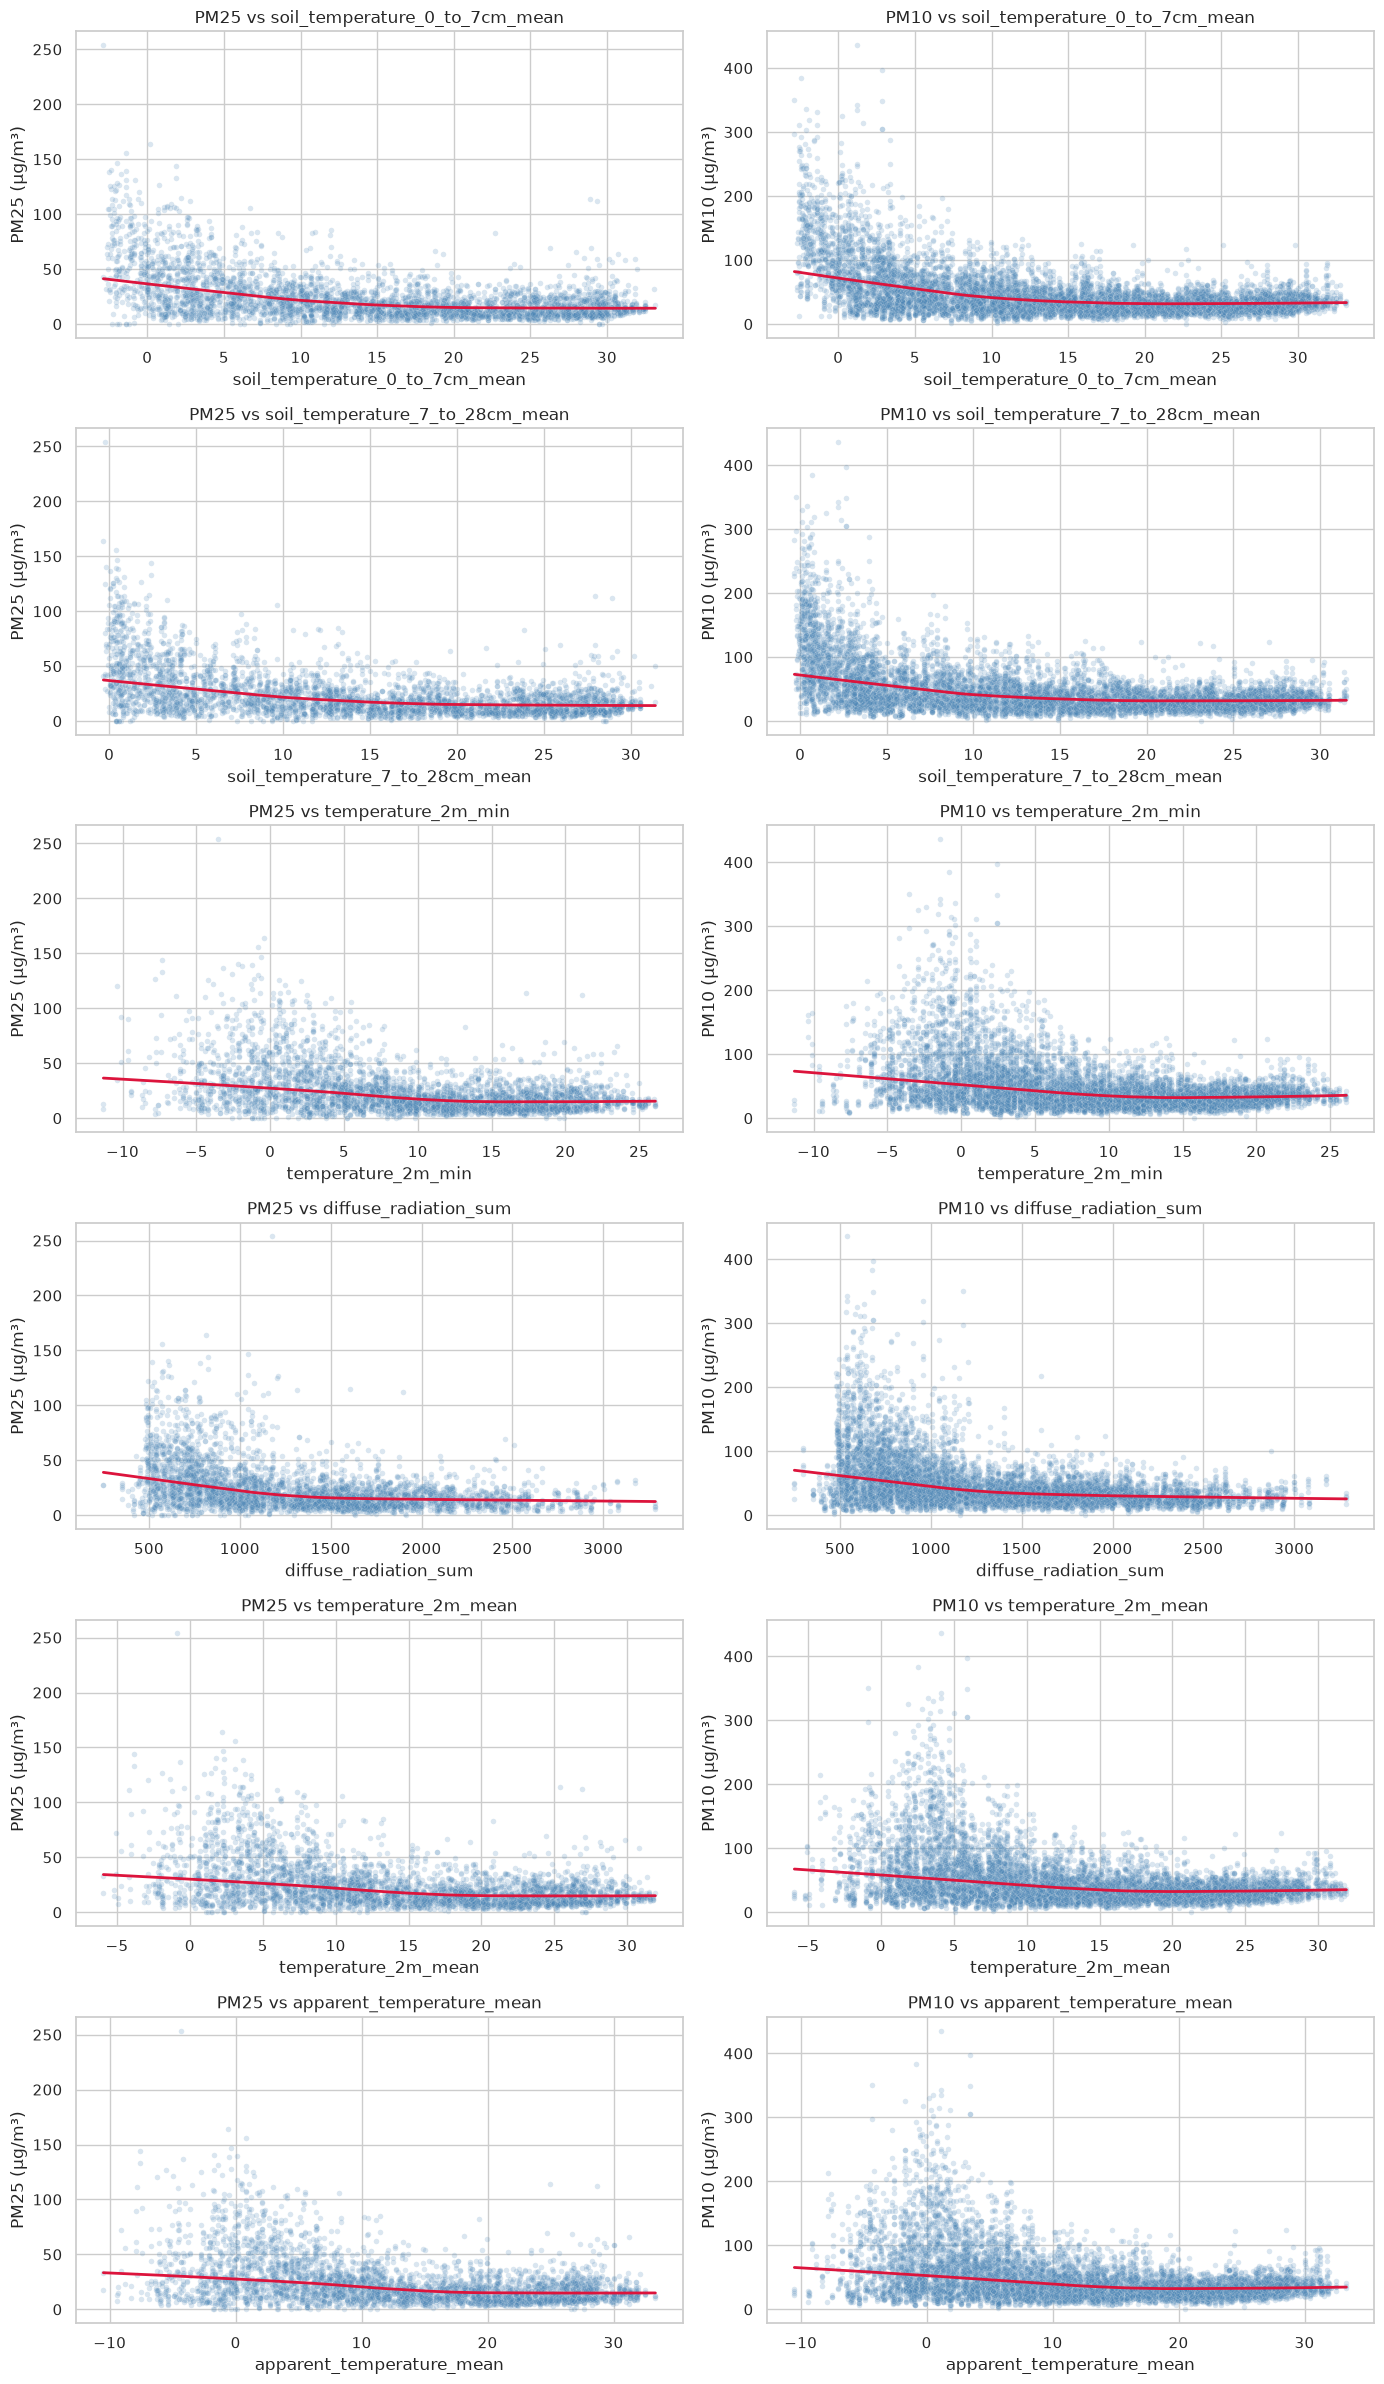

In [18]:
top_features = target_corr.head(6).index.tolist()

fig, axes = plt.subplots(
    len(top_features),
    2,
    figsize=(14, 4 * len(top_features)),
)

for row, feature in enumerate(top_features):
    for col, target in enumerate(TARGETS):
        ax = axes[row, col]

        plot_df = df[[feature, target]].dropna()

        sns.scatterplot(
            data=plot_df,
            x=feature,
            y=target,
            alpha=0.20,
            s=16,
            color="steelblue",
            ax=ax,
        )

        sns.regplot(
            data=plot_df,
            x=feature,
            y=target,
            scatter=False,
            lowess=True,
            color="crimson",
            line_kws={"linewidth": 2},
            ax=ax,
        )

        ax.set_title(f"{target.upper()} vs {feature}")
        ax.set_ylabel(f"{target.upper()} (µg/m³)")

plt.tight_layout()
plt.show()


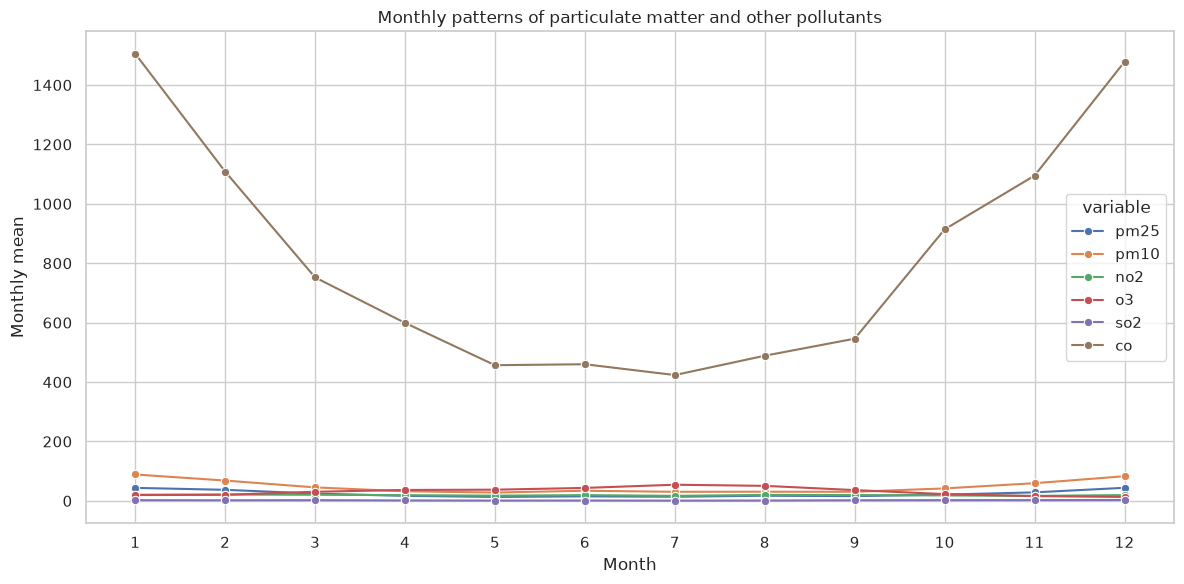

In [19]:
candidate_pollutants = [
    col for col in ["no2", "o3", "so2", "co"]
    if col in df.columns
]

monthly_pollutants = (
    df.groupby("month")[TARGETS + candidate_pollutants]
    .mean()
    .reset_index()
)

monthly_long = monthly_pollutants.melt(
    id_vars="month",
    var_name="variable",
    value_name="mean_value",
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_long,
    x="month",
    y="mean_value",
    hue="variable",
    marker="o",
)

plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Monthly mean")
plt.title("Monthly patterns of particulate matter and other pollutants")
plt.tight_layout()
plt.show()
